In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score

In [2]:
iris = load_iris()

X = pd.DataFrame(iris.data, columns=iris.feature_names)
actual_species = pd.Series(
    iris.target, name="Actual_Species"
)

print("Dataset shape:", X.shape)
display(X.head())
print("\\nSpecies names:", iris.target_names)

Dataset shape: (150, 4)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


\nSpecies names: ['setosa' 'versicolor' 'virginica']


In [3]:
print("Feature columns:")
print(X.columns.tolist())

print("\\nSummary statistics:")
display(X.describe())

print("\\nMissing values:", X.isnull().sum().sum())

Feature columns:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
\nSummary statistics:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


\nMissing values: 0


In [4]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Standardized data shape:", X_scaled.shape)

Standardized data shape: (150, 4)


In [5]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans.fit_predict(X_scaled)

print("K-Means clustering completed.")

K-Means clustering completed.


In [6]:
clustered_data = X.copy()
clustered_data["Cluster"] = cluster_labels
clustered_data["Actual_Species"] = iris.target_names[actual_species]

display(clustered_data.head(10))

print("\\nNumber of observations in each cluster:")
print(clustered_data["Cluster"].value_counts().sort_index())

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Cluster,Actual_Species
0,5.1,3.5,1.4,0.2,1,setosa
1,4.9,3.0,1.4,0.2,1,setosa
2,4.7,3.2,1.3,0.2,1,setosa
3,4.6,3.1,1.5,0.2,1,setosa
4,5.0,3.6,1.4,0.2,1,setosa
5,5.4,3.9,1.7,0.4,1,setosa
6,4.6,3.4,1.4,0.3,1,setosa
7,5.0,3.4,1.5,0.2,1,setosa
8,4.4,2.9,1.4,0.2,1,setosa
9,4.9,3.1,1.5,0.1,1,setosa


\nNumber of observations in each cluster:
Cluster
0    53
1    50
2    47
Name: count, dtype: int64


In [7]:
inertia = kmeans.inertia_
silhouette = silhouette_score(X_scaled, cluster_labels)
ari = adjusted_rand_score(actual_species, cluster_labels)

print("Inertia:", round(inertia, 4))
print("Silhouette Score:", round(silhouette, 4))
print("Adjusted Rand Index (compared with known species):", round(ari, 4))

Inertia: 139.8205
Silhouette Score: 0.4599
Adjusted Rand Index (compared with known species): 0.6201


In [8]:
cluster_comparison = pd.crosstab(
    pd.Series(iris.target_names[actual_species], name="Actual Species"),
    pd.Series(cluster_labels, name="K-Means Cluster")
)

display(cluster_comparison)

K-Means Cluster,0,1,2
Actual Species,,,
setosa,0,50,0
versicolor,39,0,11
virginica,14,0,36


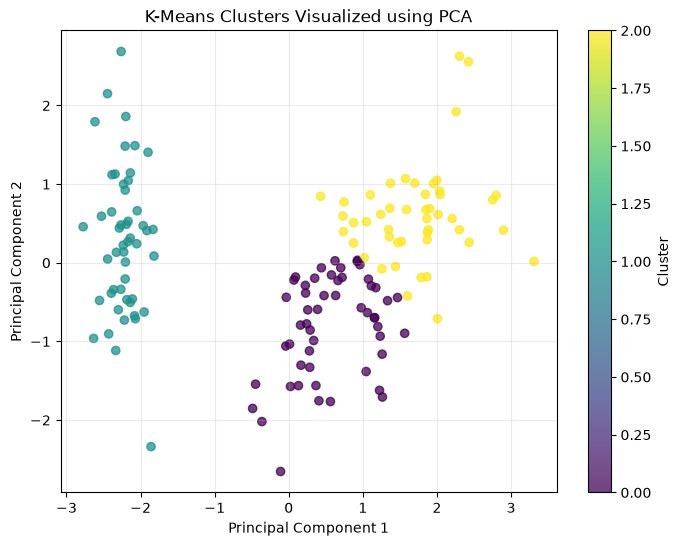

Variance retained by 2D PCA: 95.81 %


In [9]:
pca = PCA(n_components=2)
X_2d = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    X_2d[:, 0], X_2d[:, 1],
    c=cluster_labels, cmap="viridis",
    alpha=0.75
)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clusters Visualized using PCA")
plt.colorbar(scatter, label="Cluster")
plt.grid(alpha=0.25)
plt.show()

print("Variance retained by 2D PCA:",
      round(pca.explained_variance_ratio_.sum() * 100, 2), "%")

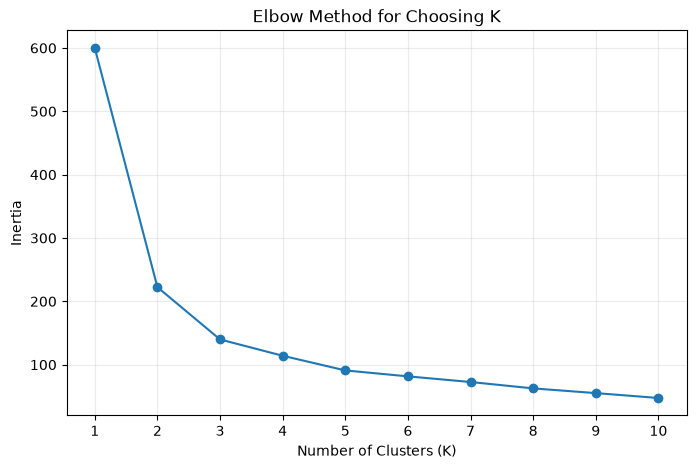

In [10]:
inertia_values = []
k_values = range(1, 11)

for k in k_values:
    km = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    km.fit(X_scaled)
    inertia_values.append(km.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_values, inertia_values, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Choosing K")
plt.xticks(list(k_values))
plt.grid(alpha=0.25)
plt.show()

In [11]:
new_flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=iris.feature_names
)

new_flower_scaled = scaler.transform(new_flower)
predicted_cluster = kmeans.predict(new_flower_scaled)[0]

print("Assigned cluster:", predicted_cluster)

Assigned cluster: 1
